Saved: confusion_matrix_raw_data_results.png


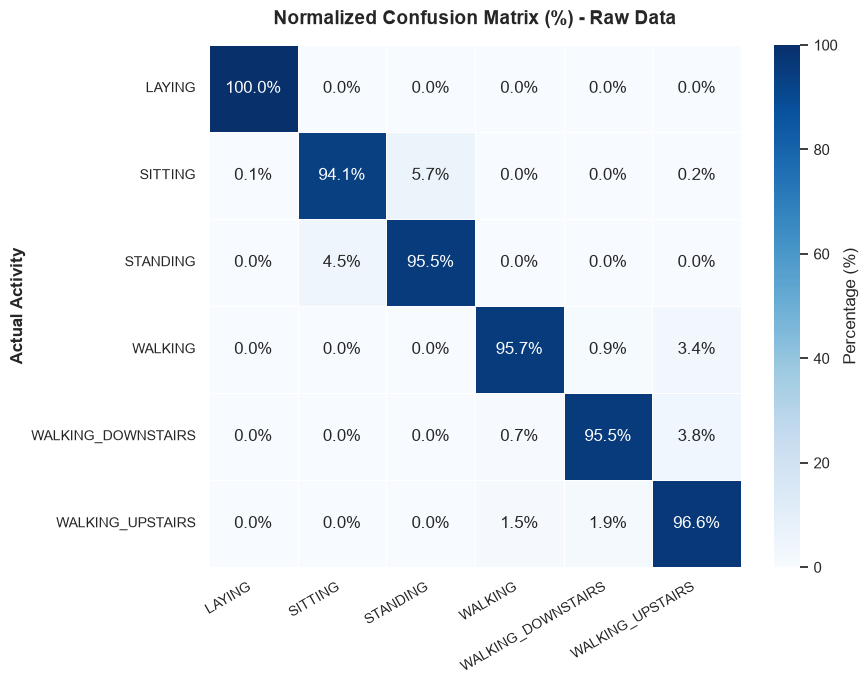

Saved: confusion_matrix_pruned_data_results.png


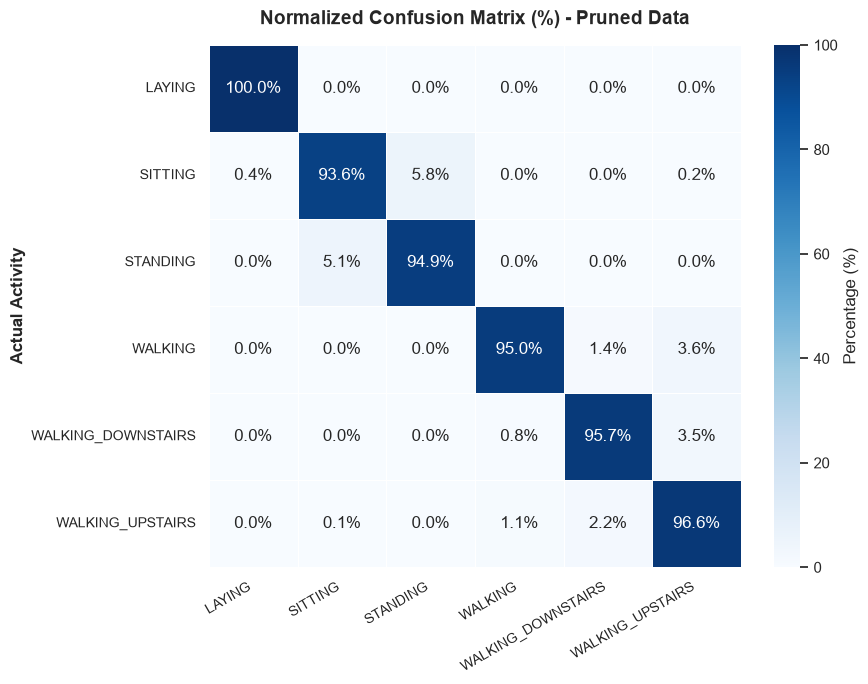

Saved: confusion_matrix_pca_data_results.png


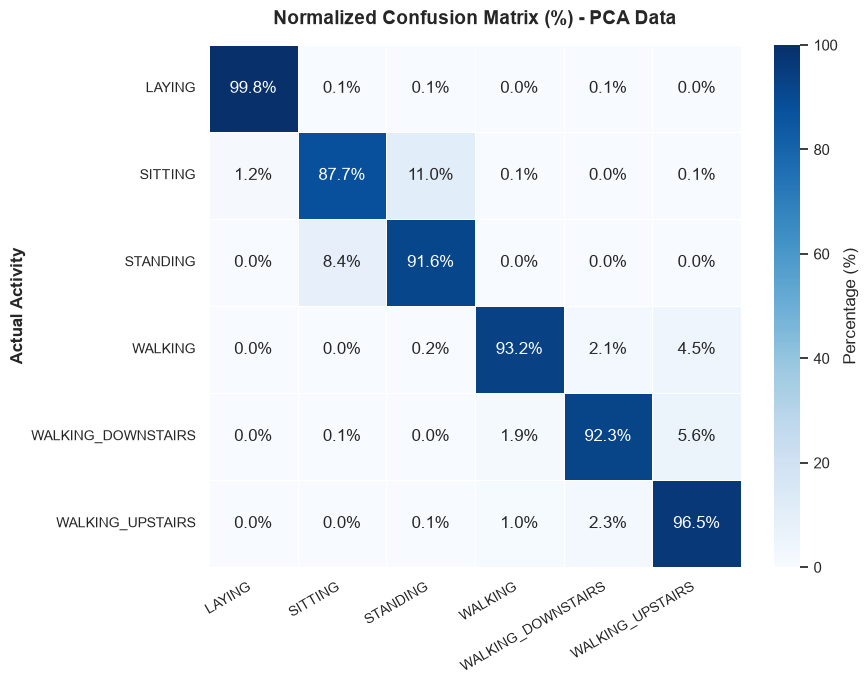

In [3]:
import json
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def load_malformed_json(file_path):
    """Reads a file and safely extracts valid JSON objects despite syntax issues."""
    with open(file_path, "r", encoding="utf-8") as f:
        content = f.read().strip()

    try:
        return json.loads(content)
    except json.JSONDecodeError:
        pass

    decoder = json.JSONDecoder()
    idx = 0
    parsed_objects = []

    while idx < len(content):
        match = re.search(r"[\{\[]", content[idx:])
        if not match:
            break
        idx += match.start()

        try:
            obj, end = decoder.raw_decode(content, idx)
            parsed_objects.append(obj)
            idx = end
        except json.JSONDecodeError:
            idx += 1

    return parsed_objects[0] if len(parsed_objects) == 1 else parsed_objects


def plot_individual_confusion_matrices(json_file_path):
    data = load_malformed_json(json_file_path)
    instance = data[0] if isinstance(data, list) else data

    pipelines = {
        "Raw Data": "raw_data_results",
        "Pruned Data": "pruned_data_results",
        "PCA Data": "pca_data_results",
    }

    # Set aesthetic theme
    sns.set_theme(style="white")

    for title, pipeline_key in pipelines.items():
        if pipeline_key not in instance:
            continue

        # Extract confusion matrix dictionary
        cm_dict = instance[pipeline_key]["final_results"][
            "confusion_matrix_pct"
        ]

        # Convert to DataFrame (Transpose so outer keys = Actual Rows)
        cm_df = pd.DataFrame(cm_dict).T

        # Format annotations with '%' symbol (e.g. 99.8%)
        annot_matrix = cm_df.map(lambda x: f"{x:.1f}%")

        # Create an individual figure for each pipeline
        fig, ax = plt.subplots(figsize=(9, 7))

        # Heatmap in Blue matching reference image
        sns.heatmap(
            cm_df,
            annot=annot_matrix,
            fmt="",
            cmap="Blues",
            vmin=0,
            vmax=100,
            cbar_kws={"label": "Percentage (%)"},
            ax=ax,
            linewidths=0.5,
            linecolor="white",
        )

        # Labels & Title formatting
        ax.set_title(
            f"Normalized Confusion Matrix (%) - {title}",
            fontsize=14,
            fontweight="bold",
            pad=15,
        )
        ax.set_ylabel("Actual Activity", fontsize=12, fontweight="bold")
        ax.set_xlabel("", fontsize=12)

        # Tick rotations matching reference image
        plt.xticks(rotation=30, ha="right", fontsize=10)
        plt.yticks(rotation=0, fontsize=10)

        plt.tight_layout()

        # Save individually
        filename = f"confusion_matrix_{pipeline_key}.png"
        plt.savefig(filename, dpi=300, bbox_inches="tight")
        print(f"Saved: {filename}")

        # Display plot one by one
        plt.show()


if __name__ == "__main__":
    plot_individual_confusion_matrices(
        r"/Users/jonaskarlsen/Desktop/Untitled-3.json"
    )